# 04 LightGBM 기반 MICE 결측치 보완

1. 원본 데이터와 보완할 센서 확인
2. 전체 기간에 LightGBM 반복 대체 모델 적합
3. 전체 기간 변환 및 센서별 보완 건수 확인
4. 결과 CSV 저장과 원본 보존 검증
5. 센서별 원본값과 보완값 그래프

`sensor_15`, `sensor_50`을 제외한 원본 센서 50개를 대상으로 합니다. 각 센서의 결측값은 **같은 행의 다른 센서값**으로 추정합니다. 2018년 4월 1일~8월 31일의 전체 기록을 사용합니다. 이 결과는 전체 기간을 살펴보기 위한 결과입니다. 이 노트북은 결정론적 반복 대체로 완성 데이터셋 한 개를 만듭니다.

실행 환경에는 `pandas`, `numpy`, `scikit-learn`, `lightgbm`이 필요합니다. LightGBM이 없는 커널에서는 먼저 `%pip install lightgbm==4.6.0`으로 설치할 수 있습니다. 결과는 `data/processed/sensor_lightgbm_mice_full_period.csv`에 저장됩니다.

## 1. 원본 데이터와 대상 센서 확인

원본 행 순서와 시간·상태를 보존합니다. 50개 대상 센서가 모두 비어 있는 행은 적합에 사용하지 않고 해당 행의 개수는 아래에 표시합니다.

In [ ]:
from pathlib import Path
import sys
import warnings

import lightgbm
from lightgbm import LGBMRegressor
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
# IterativeImputer를 사용하기 전에 실험 기능을 활성화합니다.
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer

cwd = Path.cwd()
project_root = next(
    (folder for folder in (cwd, *cwd.parents)
     if (folder / "src" / "pump_missingness_audit.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("kkobugi 저장소 또는 notebooks 폴더에서 실행하세요.")

sys.path.insert(0, str(project_root))
from src.pump_missingness_audit import default_source, read_sensor_data

source = default_source()
raw = read_sensor_data(source)
excluded = ["sensor_15", "sensor_50"]
sensor_columns = [column for column in raw if column.startswith("sensor_") and column not in excluded]
sensor_values = raw[sensor_columns].astype("float64")
timestamps = pd.to_datetime(raw["timestamp"], errors="raise")
if timestamps.isna().any() or timestamps.duplicated().any() or not timestamps.is_monotonic_increasing:
    raise ValueError("원본 시각의 결측·중복·정렬 상태를 확인하세요.")

missing = sensor_values.isna()
all_sensors_missing = missing.all(axis=1)
fit_rows = ~all_sensors_missing
if not fit_rows.any() or sensor_values.loc[fit_rows].notna().sum().eq(0).any():
    raise ValueError("학습 구간에서 관측값이 없는 대상 센서가 있는지 확인하세요.")

print(f"입력 {len(raw):,}행 · 대상 센서 {len(sensor_columns)}개")
print(f"원본 결측 {int(missing.sum().sum()):,}셀 · 전체 센서 결측 {int(all_sensors_missing.sum()):,}행")
print(f"전체 기간 적합에 사용하는 행 {int(fit_rows.sum()):,}개")
print(f"기록 기간 {timestamps.iloc[0]} ~ {timestamps.iloc[-1]}")
print(f"LightGBM {lightgbm.__version__} · scikit-learn {sklearn.__version__}")

입력 220,320행 · 대상 센서 50개
원본 결측 47,237셀 · 전체 센서 결측 11행
전체 기간 적합에 사용하는 행 220,309개
기록 기간 2018-04-01 00:00:00 ~ 2018-08-31 23:59:00
LightGBM 4.6.0 · scikit-learn 1.9.0


## 2. LightGBM 반복 대체 모델 적합

전체 기간에서 관측이 있는 행의 센서별 중앙값을 초기값으로 사용합니다. 이후 센서마다 LightGBM 회귀를 학습해 결측값을 순서대로 갱신합니다. 다른 센서를 최대 15개 사용하고, 반복 상한은 4회로 설정했습니다. `timestamp`와 `machine_status`는 결과에 함께 보존됩니다.

In [ ]:
regressor = LGBMRegressor(
    objective="regression",
    n_estimators=48,
    learning_rate=0.08,
    num_leaves=31,
    min_child_samples=30,
    max_bin=63,
    n_jobs=4,
    random_state=42,
    verbosity=-1,
    deterministic=True,
    force_col_wise=True,
)
imputer = IterativeImputer(
    estimator=regressor,
    initial_strategy="median",
    n_nearest_features=15,
    max_iter=4,
    skip_complete=False,
    sample_posterior=False,
    random_state=42,
)
# 전체 기간에서 모든 센서가 비어 있는 행을 제외하고 대체 모델을 적합합니다.
# ndarray 입력에서 LightGBM과 scikit-learn 간 중복 이름 경고만 숨깁니다.
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", message="X does not have valid feature names.*LGBMRegressor", category=UserWarning
    )
    imputer.fit(sensor_values.loc[fit_rows].to_numpy())
print(f"학습 반복 {imputer.n_iter_}회 · 적합한 센서 회귀 {len(imputer.imputation_sequence_)}개")

학습 반복 4회 · 적합한 센서 회귀 200개


C:\Users\zhfep\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


## 3. 전체 기간 변환과 결과 확인

학습한 모델로 원본 전체를 변환하고 결측 위치에만 추정값을 넣습니다. 모든 센서가 비어 있었던 행의 값은 초기 학습 중앙값에 의존한 추정입니다.

In [ ]:
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", message="X does not have valid feature names.*LGBMRegressor", category=UserWarning
    )
    estimates = imputer.transform(sensor_values.to_numpy())
if estimates.shape != sensor_values.shape or not np.isfinite(estimates).all():
    raise ValueError("보완 결과의 열 수 또는 유한값을 확인하세요.")

original_values = sensor_values.to_numpy()
missing_mask = missing.to_numpy()
# 원본에 값이 있는 셀은 모델이 반환한 값과 관계없이 원본을 그대로 사용합니다.
completed_values = np.where(missing_mask, estimates, original_values)
assert np.array_equal(completed_values[~missing_mask], original_values[~missing_mask])
export_columns = ["timestamp", *sensor_columns, "machine_status"]
result = raw.loc[:, export_columns].copy()
result[sensor_columns] = completed_values
assert result["timestamp"].equals(raw["timestamp"])
assert result["machine_status"].equals(raw["machine_status"])

remaining = result[sensor_columns].isna().sum()
audit = pd.DataFrame({
    "보완 전 결측": missing.sum(),
    "보완 후 결측": remaining,
})
print(f"센서 결측 {int(audit['보완 전 결측'].sum()):,} → {int(remaining.sum()):,}셀")
display(audit.sort_values("보완 전 결측", ascending=False).head(12))

센서 결측 47,237 → 0셀


,보완 전 결측,보완 후 결측
sensor_51,15383,0
sensor_00,10208,0
sensor_07,5451,0
sensor_08,5107,0
sensor_06,4798,0
sensor_09,4595,0
sensor_01,369,0
sensor_30,261,0
sensor_29,72,0
sensor_32,68,0


## 4. 별도 CSV 저장

시각, 보완한 센서 50개, 설비 상태를 저장합니다. CSV를 다시 읽어 센서값, 시각과 상태가 일치하는지 확인합니다.

In [ ]:
output_path = project_root / "data/processed/sensor_lightgbm_mice_full_period.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
temp_output = output_path.with_suffix(".csv.tmp")

# 재검증을 통과한 CSV만 최종 이름으로 교체합니다.
try:
    result.to_csv(temp_output, index=False)
    saved = pd.read_csv(temp_output, float_precision="round_trip")
    assert list(saved.columns) == export_columns
    assert len(saved) == len(raw)
    assert np.isfinite(saved[sensor_columns].to_numpy()).all()
    assert np.array_equal(saved[sensor_columns].to_numpy(), completed_values)
    for column in ("timestamp", "machine_status"):
        assert saved[column].equals(raw[column]), column
    temp_output.replace(output_path)
finally:
    temp_output.unlink(missing_ok=True)

print(f"저장: {output_path.relative_to(project_root).as_posix()}")
print(f"검증: {len(saved):,}행 · 센서 {len(sensor_columns)}개 · 센서 결측 0셀")

저장: data/processed/sensor_lightgbm_mice_full_period.csv
검증: 220,320행 · 센서 50개 · 센서 결측 0셀


## 5. 전체 기간의 원본값과 보완값 비교

센서 50개 각각에 대해 파란색은 원본 관측값, 주황색은 원래 결측이었던 위치에 들어간 추정값입니다. 아래쪽 주황색 줄은 원본 결측 구간을 표시합니다. `figures/lightgbm_mice_full_period/`에 PNG를 저장합니다.

그래프 50개 저장: figures/lightgbm_mice_full_period/


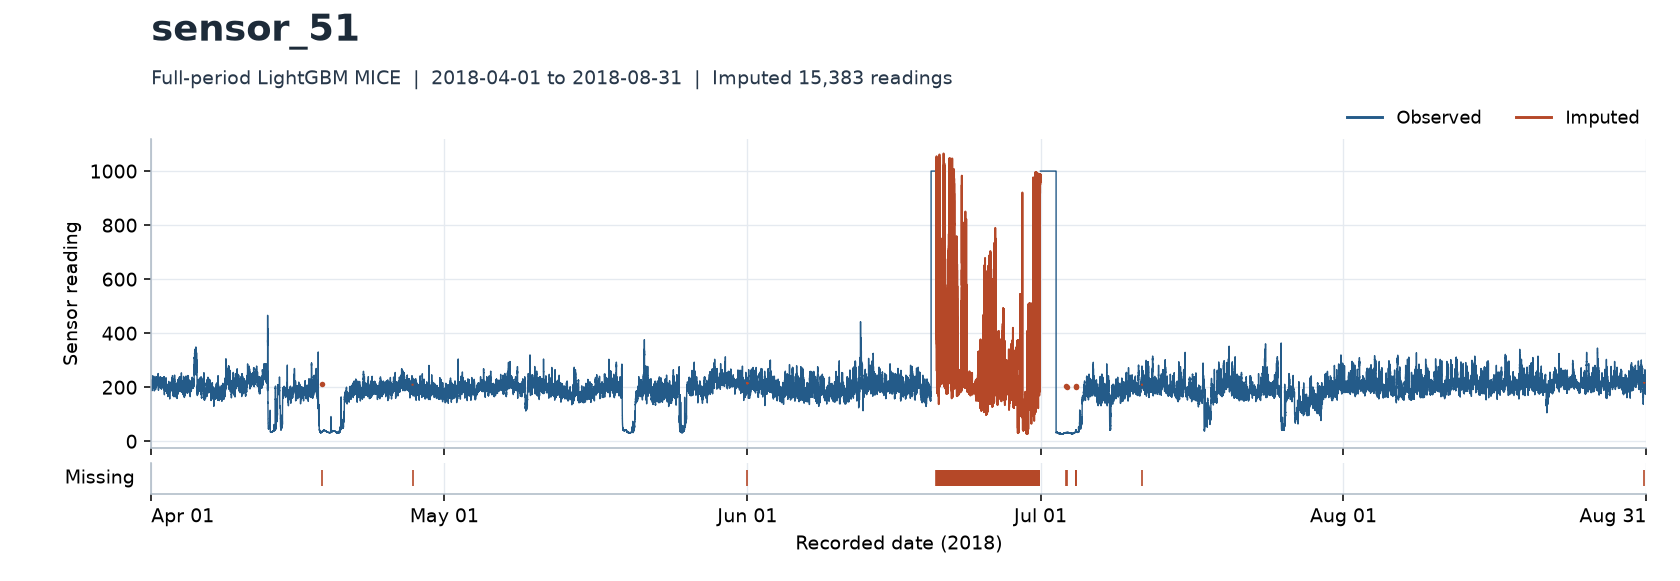

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import Image
from matplotlib.lines import Line2D

figure_dir = project_root / "figures/lightgbm_mice_full_period"
figure_dir.mkdir(parents=True, exist_ok=True)
start_time, end_time = timestamps.iloc[0], timestamps.iloc[-1]
elapsed = (timestamps - start_time) / pd.Timedelta(minutes=1)
ticks = pd.DatetimeIndex([start_time, *pd.date_range(start_time, end_time, freq="MS"), end_time]).unique()
tick_positions = (ticks - start_time) / pd.Timedelta(minutes=1)
observed_color, imputed_color = "#245b89", "#b54828"

def save_comparison_plot(sensor):
    """원본 관측값, 결측 위치의 추정값, 원본 결측 구간을 같은 시간축에 표시합니다."""
    missing_mask = missing[sensor].to_numpy()
    original = sensor_values[sensor].to_numpy()
    imputed = result[sensor].where(missing[sensor]).to_numpy()
    edges = np.flatnonzero(np.diff(np.r_[False, missing_mask, False]))
    starts, ends = edges[::2], edges[1::2]
    widths = ends - starts
    fig, (ax, gap_axis) = plt.subplots(
        2, 1, figsize=(12, 4.15), sharex=True,
        gridspec_kw={"height_ratios": [10, 1]},
    )
    fig.subplots_adjust(left=.09, right=.98, bottom=.15, top=.76, hspace=.09)
    fig.text(.09, .93, sensor, fontsize=19, fontweight="bold", color="#1d2b39")
    fig.text(
        .09, .855,
        f"Full-period LightGBM MICE  |  {start_time:%Y-%m-%d} to {end_time:%Y-%m-%d}"
        f"  |  Imputed {int(missing_mask.sum()):,} readings",
        fontsize=10, color="#28384a",
    )
    ax.plot(elapsed, original, color=observed_color, linewidth=.72)
    ax.plot(elapsed, imputed, color=imputed_color, linewidth=1.0)
    # 결측이 한 시점뿐인 경우에도 점으로 표시합니다.
    single = starts[widths == 1]
    if single.size:
        ax.scatter(elapsed.iloc[single], imputed[single], color=imputed_color, s=8, linewidths=0)
    handles = [
        Line2D([0], [0], color=observed_color, label="Observed"),
        Line2D([0], [0], color=imputed_color, label="Imputed"),
    ]
    ax.legend(handles=handles, loc="lower right", bbox_to_anchor=(1, 1.015),
              frameon=False, ncol=2, fontsize=9, borderaxespad=0)
    ax.set_ylabel("Sensor reading")
    ax.grid(True, color="#e5eaf0", linewidth=.7)
    ax.set_axisbelow(True)

    if starts.size:
        gap_axis.broken_barh(
            [(float(elapsed.iloc[start]) - .5, int(width)) for start, width in zip(starts, widths)],
            (.24, .52), facecolors=imputed_color, linewidth=0,
        )
        gap_axis.vlines(elapsed.iloc[starts], .24, .76, colors=imputed_color, linewidth=.85)
    gap_axis.set_ylim(0, 1)
    gap_axis.set_yticks([])
    gap_axis.set_ylabel("Missing", rotation=0, va="center", ha="right")
    gap_axis.yaxis.set_label_coords(-.011, .5)
    gap_axis.set_xticks(tick_positions, ticks.strftime("%b %d"))
    labels = gap_axis.get_xticklabels()
    labels[0].set_horizontalalignment("left")
    labels[-1].set_horizontalalignment("right")
    gap_axis.set_xlabel(f"Recorded date ({start_time:%Y})")
    gap_axis.set_xlim(-.5, float(elapsed.iloc[-1]) + .5)
    gap_axis.grid(True, axis="x", color="#e5eaf0", linewidth=.7)
    gap_axis.set_axisbelow(True)
    for axis in (ax, gap_axis):
        axis.spines[["top", "right"]].set_visible(False)
    try:
        fig.savefig(figure_dir / f"{sensor}.png", dpi=140, facecolor="white")
    finally:
        plt.close(fig)

# 원본 1분 측정값을 그대로 그립니다.
with plt.rc_context({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": "#aebac6", "path.simplify": False, "agg.path.chunksize": 10000,
}):
    for sensor in sensor_columns:
        save_comparison_plot(sensor)

print(f"그래프 {len(sensor_columns)}개 저장: {figure_dir.relative_to(project_root).as_posix()}/")
display(Image(filename=str(figure_dir / "sensor_51.png"), width=950))